# IAU Projekt - fáza 2

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.stats as sm_stats
import sklearn
import category_encoders as ce

In [2]:
RANDOM_SEED = 1

### 2.1 Realizácia predspracovania dát

Nacitame data z readings a units a gateway. Z units budeme brať do úvahy atribúty year_commission, dutyClass, hours_service. Z gateways budeme brať do úvahy atribúť version_firmware, kedže koreloval s predikovanou premennou failure. Z readings odstránim atribút ts_cycle, ktorý označuje dátum merania, ktorý by nemal byť relevantný pre predikciu poruchy.

In [3]:
READINGS = "readings.csv"
readings_df = pd.read_csv(READINGS, delimiter="\t", parse_dates=["ts_cycle"], date_format="mixed")
readings_df["id_unit"] = readings_df["id_unit"].str.replace("U", "").astype(int)
readings_df.drop_duplicates(inplace=True)

UNITS = "units.csv"
units_df = pd.read_csv(UNITS, delimiter=",")
units_df["dutyClass"] = units_df["dutyClass"].str.strip()
units_df.replace({
    "1": "light", "L": "light",
    "N": "medium", "2": "medium", "normal": "medium", "med": "medium",
    "3": "heavy", "H": "heavy"
}, inplace=True)

GATEWAYS = "gateways.csv"
gateways_df = pd.read_csv(GATEWAYS, delimiter=";", parse_dates=["last_seen", "dateInstall"], date_format="mixed")
gateways_df = gateways_df.dropna(subset="id_unit")
gateways_df["id_unit"] = gateways_df.id_unit.astype(int)

# mergenem readings, units, gateways pomocou id_unit
readings_df = readings_df.drop(columns=["ts_cycle"])
units_cols = ["year_commission", "dutyClass", "hours_service"]
gateways_cols = ["version_firmware"]
main_df = (
    readings_df
    .merge(units_df[["id_unit"] + units_cols], on="id_unit", how="inner", validate="many_to_one",)
    .merge(gateways_df[["id_unit"] + gateways_cols], on="id_unit", how="inner", validate="many_to_one")
)
main_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14129 entries, 0 to 14128
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_unit            14129 non-null  int64  
 1   motor_current      14129 non-null  float64
 2   dpFilter           13590 non-null  float64
 3   temperature_oil    14129 non-null  float64
 4   reservoirPressure  14129 non-null  float64
 5   oilPressure        14129 non-null  float64
 6   rms_vibration      13575 non-null  float64
 7   Flowmeter          14129 non-null  float64
 8   humidityIntake     13448 non-null  float64
 9   failure            14129 non-null  int64  
 10  year_commission    14129 non-null  int64  
 11  dutyClass          14129 non-null  str    
 12  hours_service      13401 non-null  float64
 13  version_firmware   14129 non-null  str    
dtypes: float64(9), int64(3), str(2)
memory usage: 1.7 MB


### Rozdelenie na trenovacu a testovaciu množinu
Data náhodne rozdelime na trenovaciu a testovaciu množinu. 80% dat bude sluzit na trenovanie a 20% dat na testovanie.

In [4]:
train_df, test_df = sklearn.model_selection.train_test_split(main_df, test_size=0.2, random_state=RANDOM_SEED)

### Zadkovovanie kategorických premenných na numerické 
`dutyClass` - kedze tento atribut m jasné usporiadanie (light < medium < heavy) použijeme ordinal encoding

`version_firmware` - v dátach sú iba 3 rôzne verzie, preto použijeme one-hot encoding

In [5]:
mapping = [{'col': 'dutyClass', 'mapping': {'light': 1, 'medium': 2, 'heavy': 3}}]
ordinal_encoder = ce.OrdinalEncoder(mapping=mapping)
train_df = ordinal_encoder.fit_transform(train_df)
onehot_encoder = ce.OneHotEncoder(cols=["version_firmware"])
train_df = onehot_encoder.fit_transform(train_df)

In [6]:
train_df.info()

<class 'pandas.DataFrame'>
Index: 11303 entries, 9769 to 13349
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_unit             11303 non-null  int64  
 1   motor_current       11303 non-null  float64
 2   dpFilter            10886 non-null  float64
 3   temperature_oil     11303 non-null  float64
 4   reservoirPressure   11303 non-null  float64
 5   oilPressure         11303 non-null  float64
 6   rms_vibration       10849 non-null  float64
 7   Flowmeter           11303 non-null  float64
 8   humidityIntake      10755 non-null  float64
 9   failure             11303 non-null  int64  
 10  year_commission     11303 non-null  int64  
 11  dutyClass           11303 non-null  int64  
 12  hours_service       10721 non-null  float64
 13  version_firmware_1  11303 non-null  int64  
 14  version_firmware_2  11303 non-null  int64  
 15  version_firmware_3  11303 non-null  int64  
dtypes: float64(9), in

### Vyriešenie problemov identifikovaných v fáze 1
Hodotnu `-999` z atribútu `temperature_oil` prevedieme na chýbajúcu hodnotu. 
pčet chýbajúcich hodnôt pre hours_service je 728 z 14129 čo je 5.15%. Kedže ide o viac ako 5% použimeme KNN imputer na doplnenie chýbajúcich hodnôt.

In [7]:
train_df["temperature_oil"] = train_df["temperature_oil"].replace(-999, np.nan)

imputer = sklearn.impute.KNNImputer(n_neighbors=5)
train_df = pd.DataFrame(
    imputer.fit_transform(train_df), 
    columns=train_df.columns, 
    index=train_df.index
)

print("Pocet chybajucich hodnot po imputacii:", train_df.isnull().sum().sum())

Pocet chybajucich hodnot po imputacii: 0


Vykreslíme histogramy pre atribúty, po doplnění chýbajúcich hodnôt.

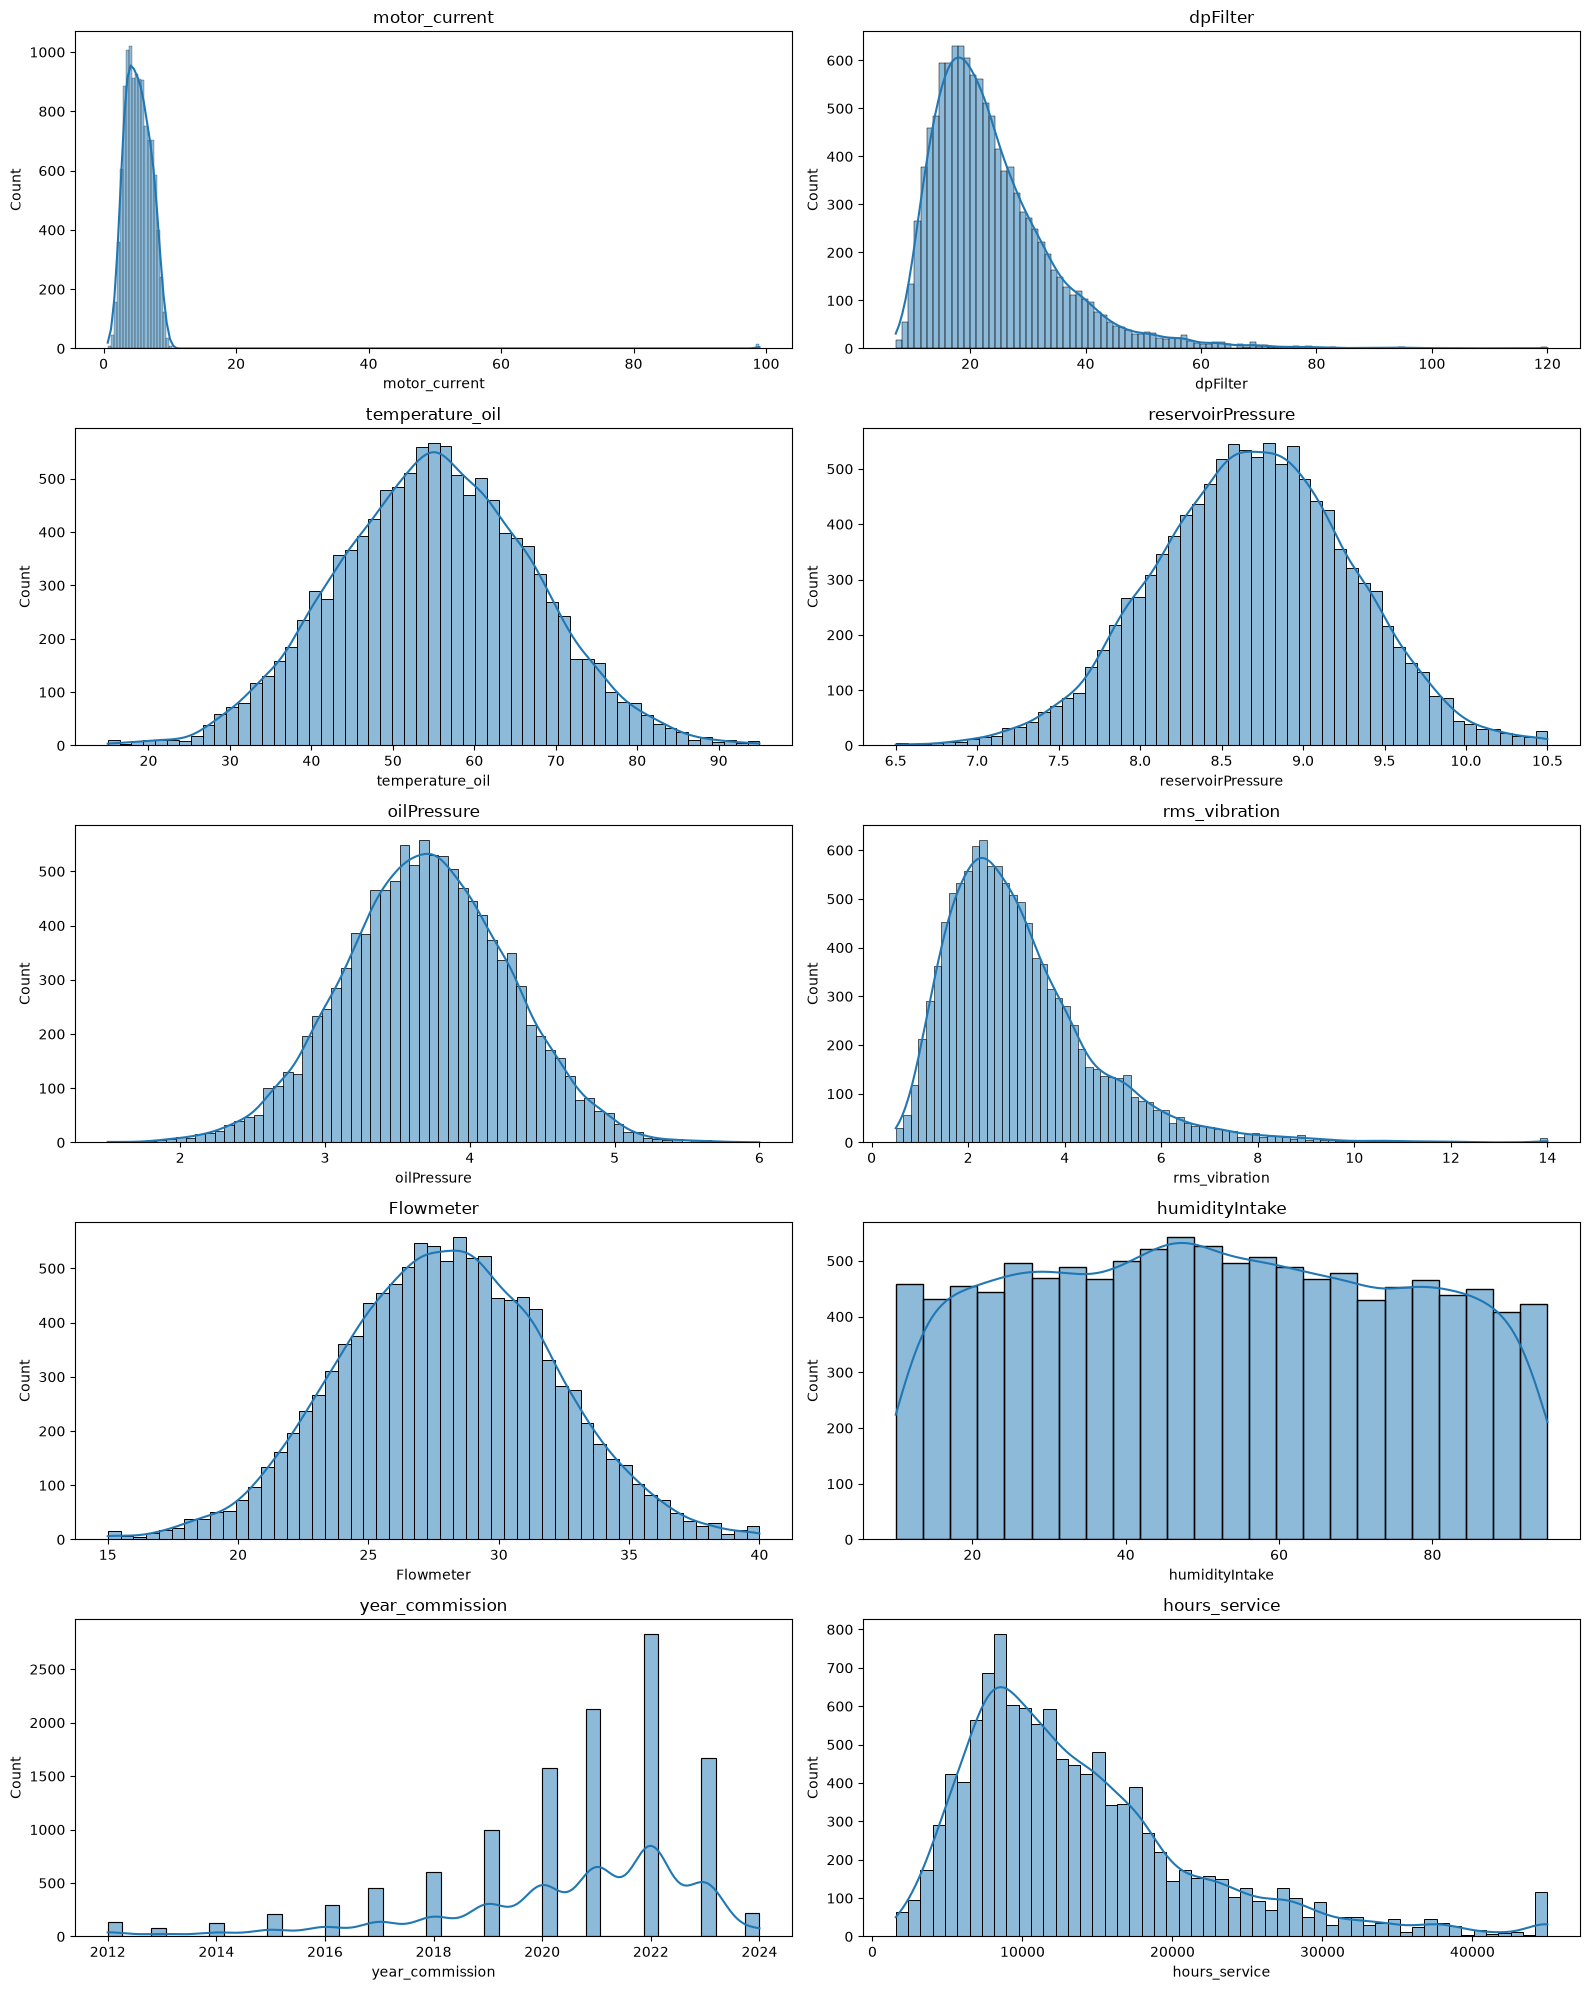

In [14]:
# Vygreslime histogramy pre pre všetky atribúty z train_df okrem id_unit, failure, dutyClass, version_firmware (1,2,3)

# Viem ze grafov bude 10, takze si vytvorim 10 subplots, 5x2
fig, axs = plt.subplots(5, 2, figsize=(16, 20))
attributes = [col for col in train_df.columns if col not in ["id_unit", "failure", "dutyClass", "version_firmware_1", "version_firmware_2", "version_firmware_3"]]
for i, attr in enumerate(attributes):
    row = i // 2
    col = i % 2
    sns.histplot(train_df[attr], ax=axs[row, col], kde=True)
    axs[row, col].set_title(attr)
    axs[row, col].set_xlabel(attr)
    axs[row, col].set_ylabel("Count")
fig.tight_layout()
plt.show()






### Odstránenie odľahlých hodnôt
Kedže pri odstranovaní odľahlých hodnôt prídeme o 2170 z 14129 záznamov, čo je 15.36% dat a pri winsorizacii nám na okrajoch distribúcie výrazne narastie počet záznamov. Najlepšie nám príde všetky odlahlé hodnoty zatial neodstraňovať ani nenahrádzat a neskôr použiť RobustScaler, ktorý je odolný voči odľahlým hodnotám.

In [ ]:
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

# vypis odlahlých hodnôt motor current cez IQR
lower_bound, upper_bound = iqr_bounds(train_df["motor_current"])
print(f"Lower bound: {lower_bound}, Upper bound: {upper_bound}")
motor_current_outliers = train_df[(train_df["motor_current"] < lower_bound) | (train_df["motor_current"] > upper_bound)]
print("motor current outliers:", motor_current_outliers["motor_current"].values)

Lower bound: -0.5862474999999994, Upper bound: 10.953332499999998
motor current outliers: [99. 99. 99. 99. 99. 99. 99. 99. 99. 99. 99. 99. 99. 99. 99.]


Všetky odľahlé hodnoty motor current sú 99 čo je výrazne odlišné od upper bound 10.95. Preto ich nahradíme hodnotou upper bound 10.95.

In [18]:
train_df.loc[train_df["motor_current"] > upper_bound, "motor_current"] = upper_bound

Ostatné odľahlé hodnoty nie su jednoznačne chybné merania, a kedže ich je celkom veľa, tak ich nebudeme odstraňovať ani nahrádzať.

### Škalovanie atribútov